In [1]:
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

LATENT_DIM = 100
LR = 2e-4
EPOCHS = 10
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(42)

C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(LATENT_DIM, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2),
            nn.Linear(1024, 784), nn.Tanh())

    def forward(self, z, labels=None):
        return self.net(z).view(-1, 1, 28, 28)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1))

    def forward(self, x, labels=None):
        return self.net(x)

In [3]:
loss_fn = nn.BCEWithLogitsLoss()

# A1: real -> 1, fake -> 0, fakes are detached so G is not updated
def discriminator_step(g, d, opt_d, real, labels=None):
    z = torch.randn(len(real), LATENT_DIM, device=DEVICE)
    fake = g(z, labels).detach()
    real_out = d(real, labels)
    fake_out = d(fake, labels)
    loss = loss_fn(real_out, torch.ones_like(real_out)) + loss_fn(fake_out, torch.zeros_like(fake_out))
    opt_d.zero_grad()
    loss.backward()
    opt_d.step()
    return loss.item()

# A2: G wants D to say 1 for fakes, only G is stepped
def generator_step(g, d, opt_g, n, labels=None):
    z = torch.randn(n, LATENT_DIM, device=DEVICE)
    out = d(g(z, labels), labels)
    loss = loss_fn(out, torch.ones_like(out))
    opt_g.zero_grad()
    loss.backward()
    opt_g.step()
    return loss.item()

In [4]:
# D1: noise + one-hot label -> (B, 110, 1, 1)
def condition_noise(z, labels):
    one_hot = F.one_hot(labels, 10).float()
    return torch.cat([z, one_hot], 1)[:, :, None, None]

# D2: image + one-hot label maps -> (B, 11, 32, 32)
def condition_images(x, labels):
    one_hot = F.one_hot(labels, 10).float()
    maps = one_hot[:, :, None, None].expand(-1, -1, x.size(2), x.size(3))
    return torch.cat([x, maps], 1)


class CondGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(110, 256, 4, 1, 0), nn.BatchNorm2d(256), nn.ReLU(),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())

    def forward(self, z, labels):
        return self.net(condition_noise(z, labels))


class CondDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(11, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2),
            nn.Conv2d(256, 1, 4, 1, 0), nn.Flatten())

    def forward(self, x, labels):
        return self.net(condition_images(x, labels))

In [5]:
def show(g, z, labels=None, title='', nrow=8):
    with torch.no_grad():
        imgs = (g(z, labels).cpu() + 1) / 2
    plt.imshow(make_grid(imgs, nrow=nrow).permute(1, 2, 0))
    plt.title(title)
    plt.axis('off')
    plt.show()

def train(conditional=False, d_lr_mult=1):
    torch.manual_seed(42)
    size = 32 if conditional else 28
    tf = transforms.Compose([transforms.Resize(size), transforms.ToTensor(), transforms.Normalize(0.5, 0.5)])
    loader = DataLoader(datasets.MNIST('data', download=True, transform=tf), batch_size=128, shuffle=True)

    if conditional:
        g, d = CondGenerator().to(DEVICE), CondDiscriminator().to(DEVICE)
    else:
        g, d = Generator().to(DEVICE), Discriminator().to(DEVICE)
    opt_g = torch.optim.Adam(g.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(d.parameters(), lr=LR * d_lr_mult, betas=(0.5, 0.999))

    d_hist, g_hist = [], []
    for epoch in range(EPOCHS):
        for x, y in loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE) if conditional else None
            dl = discriminator_step(g, d, opt_d, x, y)
            gl = generator_step(g, d, opt_g, len(x), y)
        d_hist.append(dl)
        g_hist.append(gl)
        print(f'epoch {epoch + 1}: D={dl:.3f} G={gl:.3f}')
    return g, d_hist, g_hist

epoch 1: D=0.849 G=1.402


epoch 2: D=1.002 G=2.504


epoch 3: D=0.716 G=2.224


epoch 4: D=0.829 G=1.388


epoch 5: D=0.887 G=2.061


epoch 6: D=0.958 G=1.534


epoch 7: D=1.026 G=2.485


epoch 8: D=0.803 G=1.799


epoch 9: D=0.972 G=2.238


epoch 10: D=1.060 G=2.721


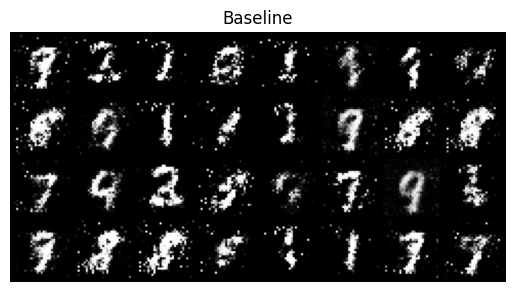

epoch 1: D=0.559 G=2.886


epoch 2: D=0.584 G=1.885


epoch 3: D=0.501 G=2.032


epoch 4: D=0.605 G=0.755


epoch 5: D=0.394 G=2.404


epoch 6: D=0.805 G=3.165


epoch 7: D=1.052 G=2.434


epoch 8: D=1.097 G=0.550


epoch 9: D=0.822 G=1.824


epoch 10: D=0.791 G=1.712


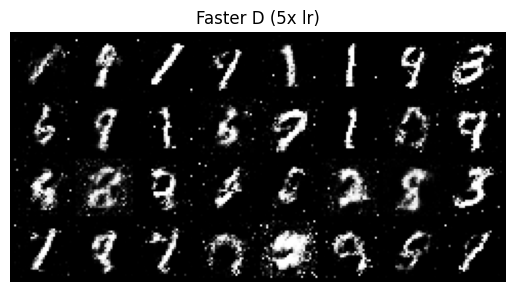

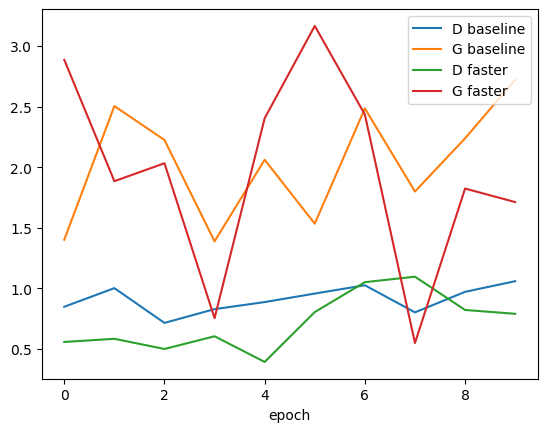

In [6]:
fixed_z = torch.randn(32, LATENT_DIM, device=DEVICE)

g_base, d_base, gl_base = train()
show(g_base, fixed_z, title='Baseline')

g_fast, d_fast, gl_fast = train(d_lr_mult=5)
show(g_fast, fixed_z, title='Faster D (5x lr)')

plt.plot(d_base, label='D baseline')
plt.plot(gl_base, label='G baseline')
plt.plot(d_fast, label='D faster')
plt.plot(gl_fast, label='G faster')
plt.xlabel('epoch')
plt.legend()
plt.show()

epoch 1: D=0.662 G=1.539


epoch 2: D=0.941 G=0.906


epoch 3: D=0.582 G=2.559


epoch 4: D=0.602 G=1.351


epoch 5: D=0.056 G=4.843


epoch 6: D=0.086 G=3.549


epoch 7: D=0.804 G=2.567


epoch 8: D=0.028 G=5.813


epoch 9: D=0.516 G=2.380


epoch 10: D=0.006 G=6.044


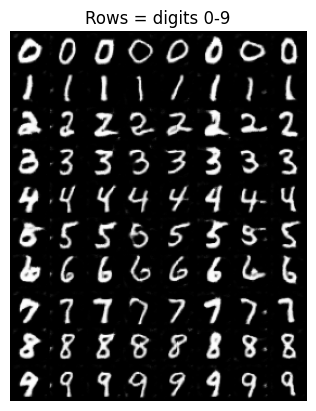

In [7]:
g_cond, d_cond, gl_cond = train(conditional=True)
g_cond.eval()

z = torch.randn(8, LATENT_DIM, device=DEVICE).repeat(10, 1)
y = torch.arange(10, device=DEVICE).repeat_interleave(8)
show(g_cond, z, y, 'Rows = digits 0-9')

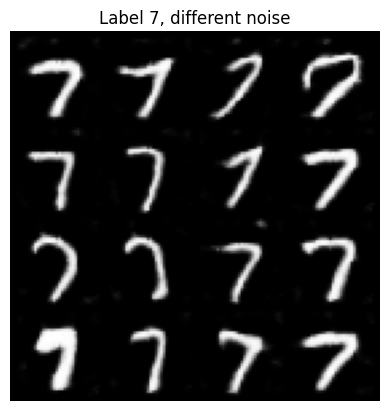

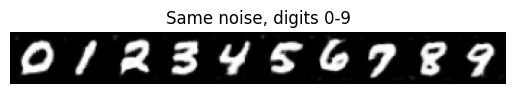

In [8]:
# same label, different noise
z = torch.randn(16, LATENT_DIM, device=DEVICE)
y = torch.full((16,), 7, device=DEVICE)
show(g_cond, z, y, 'Label 7, different noise', nrow=4)

# same noise, different labels
z = torch.randn(1, LATENT_DIM, device=DEVICE).repeat(10, 1)
y = torch.arange(10, device=DEVICE)
show(g_cond, z, y, 'Same noise, digits 0-9', nrow=10)